In [1]:
import pandas as pd
from src.fraud_detection.config import RAW_DATA_DIR


In [2]:
train = pd.read_csv(RAW_DATA_DIR / "fraudTrain.csv", index_col=0)
test = pd.read_csv(RAW_DATA_DIR / "fraudTest.csv", index_col=0)
transactions = pd.read_parquet("C:/Users/oussa/PycharmProjects/anomly_bank_detection/data/processed/transactions.parquet")
users = pd.read_parquet("C:/Users/oussa/PycharmProjects/anomly_bank_detection/data/processed/users.parquet")


In [3]:
transactions.dtypes


trans_num                           str
cc_num                            int64
trans_date_trans_time    datetime64[us]
category                            str
merchant                            str
amt                             float64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
dtype: object

In [4]:
train.shape, test.shape, transactions.shape

((1296675, 22), (555719, 22), (1296675, 9))

In [5]:
train.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
train.describe(), test.describe()

(             cc_num           amt           zip           lat          long  \
 count  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06   
 mean   4.171920e+17  7.035104e+01  4.880067e+04  3.853762e+01 -9.022634e+01   
 std    1.308806e+18  1.603160e+02  2.689322e+04  5.075808e+00  1.375908e+01   
 min    6.041621e+10  1.000000e+00  1.257000e+03  2.002710e+01 -1.656723e+02   
 25%    1.800429e+14  9.650000e+00  2.623700e+04  3.462050e+01 -9.679800e+01   
 50%    3.521417e+15  4.752000e+01  4.817400e+04  3.935430e+01 -8.747690e+01   
 75%    4.642255e+15  8.314000e+01  7.204200e+04  4.194040e+01 -8.015800e+01   
 max    4.992346e+18  2.894890e+04  9.978300e+04  6.669330e+01 -6.795030e+01   
 
            city_pop     unix_time     merch_lat    merch_long      is_fraud  
 count  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06  
 mean   8.882444e+04  1.349244e+09  3.853734e+01 -9.022646e+01  5.788652e-03  
 std    3.019564e+05  1.284128e+07  5.109

In [7]:
train[train["is_fraud"]==1]

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
2449,2019-01-02 01:06:37,4613314721966,fraud_Rutherford-Mertz,grocery_pos,281.06,Jason,Murphy,M,542 Steve Curve Suite 011,Collettsville,...,35.9946,-81.7266,885,Soil scientist,1988-09-15,e8a81877ae9a0a7f883e15cb39dc4022,1325466397,36.430124,-81.179483,1
2472,2019-01-02 01:47:29,340187018810220,"fraud_Jenkins, Hauck and Friesen",gas_transport,11.52,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,...,29.4400,-98.4590,1595797,Horticultural consultant,1960-10-28,bc7d41c41103877b03232f03f1f8d3f5,1325468849,29.819364,-99.142791,1
2523,2019-01-02 03:05:23,340187018810220,fraud_Goodwin-Nitzsche,grocery_pos,276.31,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,...,29.4400,-98.4590,1595797,Horticultural consultant,1960-10-28,b98f12f4168391b2203238813df5aa8c,1325473523,29.273085,-98.836360,1
2546,2019-01-02 03:38:03,4613314721966,fraud_Erdman-Kertzmann,gas_transport,7.03,Jason,Murphy,M,542 Steve Curve Suite 011,Collettsville,...,35.9946,-81.7266,885,Soil scientist,1988-09-15,397894a5c4c02e3c61c784001f0f14e4,1325475483,35.909292,-82.091010,1
2553,2019-01-02 03:55:47,340187018810220,fraud_Koepp-Parker,grocery_pos,275.73,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,...,29.4400,-98.4590,1595797,Horticultural consultant,1960-10-28,7863235a750d73a244c07f1fb7f0185a,1325476547,29.786426,-98.683410,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295399,2020-06-21 01:00:08,3524574586339330,fraud_Kassulke PLC,shopping_net,977.01,Ashley,Cabrera,F,94225 Smith Springs Apt. 617,Vero Beach,...,27.6330,-80.4031,105638,"Librarian, public",1986-05-07,a83b093f0c1d9068fa0089f7c722615f,1371776408,26.888686,-80.834389,1
1295491,2020-06-21 01:53:35,3524574586339330,fraud_Schumm PLC,shopping_net,1210.91,Ashley,Cabrera,F,94225 Smith Springs Apt. 617,Vero Beach,...,27.6330,-80.4031,105638,"Librarian, public",1986-05-07,f75b35bed13b9e692f170dba45a15b21,1371779615,28.216707,-79.855648,1
1295532,2020-06-21 02:16:56,4005676619255478,"fraud_Tillman, Dickinson and Labadie",gas_transport,10.24,William,Perry,M,458 Phillips Island Apt. 768,Denham Springs,...,30.4590,-90.9027,71335,Herbalist,1994-05-31,a0ba2472cd3fc9731f2a18d3f308f5c3,1371781016,29.700456,-91.361632,1
1295666,2020-06-21 03:26:20,3560725013359375,fraud_Corwin-Collins,gas_transport,21.69,Brooke,Smith,F,63542 Luna Brook Apt. 012,Notrees,...,31.8599,-102.7413,23,Cytogeneticist,1969-09-15,daa281350b1e16093c7b4bf97bf4d6ed,1371785180,32.675272,-103.484949,1


In [8]:
columns = ["trans_date_trans_time", "cc_num", "category", "amt","merchant", "is_fraud"]
train[train["cc_num"]==4922710831011201][columns]   

,trans_date_trans_time,cc_num,category,amt,merchant,is_fraud
8,2019-01-01 00:05:18,4922710831011201,misc_pos,4.27,fraud_Herzog Ltd,0
282,2019-01-01 03:42:00,4922710831011201,misc_pos,3.43,fraud_Flatley Group,0
329,2019-01-01 04:19:04,4922710831011201,shopping_net,1.91,"fraud_Reichert, Huels and Hoppe",0
4324,2019-01-03 16:54:53,4922710831011201,grocery_pos,337.05,fraud_Rau and Sons,1
4383,2019-01-03 18:07:01,4922710831011201,shopping_pos,711.66,fraud_Pouros-Conroy,1
...,...,...,...,...,...,...
1287841,2020-06-17 16:53:23,4922710831011201,kids_pets,17.53,"fraud_Streich, Rolfson and Wilderman",0
1290058,2020-06-18 19:30:50,4922710831011201,travel,4.87,"fraud_Kilback, Nitzsche and Leffler",0
1291326,2020-06-19 10:02:52,4922710831011201,gas_transport,78.23,"fraud_Connelly, Reichert and Fritsch",0
1291918,2020-06-19 15:33:41,4922710831011201,health_fitness,11.94,fraud_Jacobi Inc,0


In [9]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  str    
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  str    
 3   category               1296675 non-null  str    
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  str    
 6   last                   1296675 non-null  str    
 7   gender                 1296675 non-null  str    
 8   street                 1296675 non-null  str    
 9   city                   1296675 non-null  str    
 10  state                  1296675 non-null  str    
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop               129667

In [10]:
for df in (train, test):
    for col in ["trans_date_trans_time", "dob"]:
        df[col] = pd.to_datetime(df[col], format="%Y-%m-%d %H:%M:%S" if col == "trans_date_trans_time" else "%Y-%m-%d")

In [11]:
train.head( )

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [12]:
train.isna().sum()

trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [13]:
train.nunique()

trans_date_trans_time    1274791
cc_num                       983
merchant                     693
category                      14
amt                        52928
first                        352
last                         481
gender                         2
street                       983
city                         894
state                         51
zip                          970
lat                          968
long                         969
city_pop                     879
job                          494
dob                          968
trans_num                1296675
unix_time                1274823
merch_lat                1247805
merch_long               1275745
is_fraud                       2
dtype: int64

In [14]:
train["is_fraud"].value_counts(normalize=True), test["is_fraud"].value_counts(normalize=True)

(is_fraud
 0    0.994211
 1    0.005789
 Name: proportion, dtype: float64,
 is_fraud
 0    0.99614
 1    0.00386
 Name: proportion, dtype: float64)

In [15]:
train.trans_date_trans_time.min(), train.trans_date_trans_time.max(), test.trans_date_trans_time.min(), test.trans_date_trans_time.max()

(Timestamp('2019-01-01 00:00:18'),
 Timestamp('2020-06-21 12:13:37'),
 Timestamp('2020-06-21 12:14:25'),
 Timestamp('2020-12-31 23:59:34'))

In [16]:
train.groupby("is_fraud")["amt"].describe()


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


<Axes: ylabel='Frequency'>

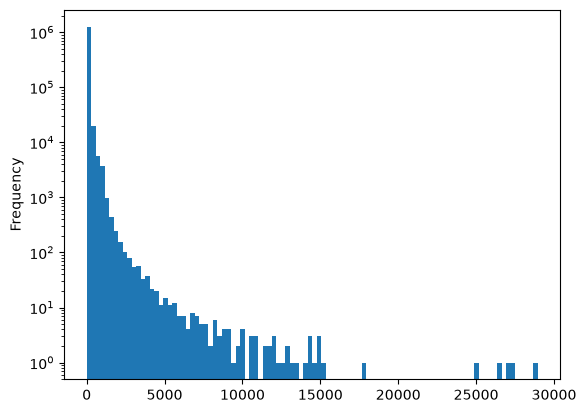

In [17]:
import matplotlib.pyplot as plt
train["amt"].plot.hist(bins=100, log=True)

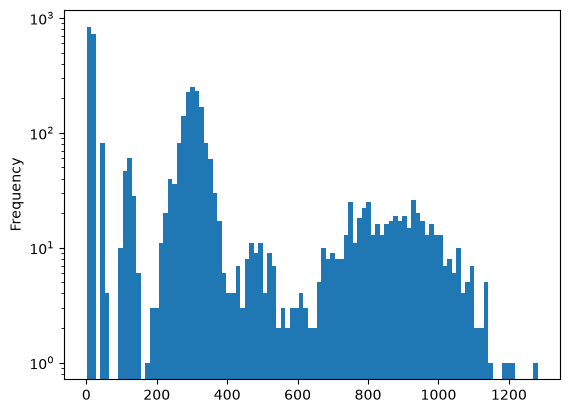

In [18]:
import matplotlib.pyplot as plt

amount_counts = train["amt"].value_counts()
repeated_amts = amount_counts[amount_counts > 1].index

filtered = train[
    train["amt"].isin(repeated_amts) &
    (train["amt"] < 1300) & train["is_fraud"]
]

filtered["amt"].plot.hist(bins=100, log=True)

plt.show()

In [19]:
train.groupby("cc_num").size().describe()

count     983.000000
mean     1319.099695
std       812.235900
min         7.000000
25%       525.000000
50%      1054.000000
75%      2025.000000
max      3123.000000
dtype: float64

In [20]:
tx_per_card = train.groupby("cc_num").size()
print("number of cards:", tx_per_card.shape[0])
tx_per_card.describe()


number of cards: 983


count     983.000000
mean     1319.099695
std       812.235900
min         7.000000
25%       525.000000
50%      1054.000000
75%      2025.000000
max      3123.000000
dtype: float64

In [21]:
fraud_per_card = train.groupby("cc_num")["is_fraud"].sum()
defrauded = fraud_per_card[fraud_per_card > 0]

print("cards with at least one fraud:", len(defrauded), "/", len(fraud_per_card))
defrauded.describe()


cards with at least one fraud: 762 / 983


count    762.000000
mean       9.850394
std        2.961191
min        2.000000
25%        8.000000
50%       10.000000
75%       12.000000
max       19.000000
Name: is_fraud, dtype: float64

In [22]:
card = 4613314721966  # Jason Murphy's card from your fraud rows
card_tx = train[train["cc_num"] == card].sort_values("trans_date_trans_time").reset_index(drop=True)

first_fraud = card_tx.index[card_tx["is_fraud"] == 1][0]
card_tx.loc[max(first_fraud - 10, 0): first_fraud + 15,["trans_date_trans_time", "category", "amt", "is_fraud"]]


,trans_date_trans_time,category,amt,is_fraud
0,2019-01-01 12:51:40,home,71.03,0
1,2019-01-02 01:06:37,grocery_pos,281.06,1
2,2019-01-02 03:38:03,gas_transport,7.03,1
3,2019-01-02 13:38:08,shopping_net,844.80,1
4,2019-01-02 23:52:08,misc_net,843.91,1
5,2019-01-03 22:21:15,shopping_net,942.62,1
6,2019-01-03 23:09:51,shopping_pos,821.96,1
7,2019-01-03 23:29:57,shopping_net,1092.68,1
8,2019-01-03 23:41:36,shopping_net,1254.27,1
9,2019-01-04 04:08:19,misc_pos,32.66,0


In [23]:
frauds = train[train["is_fraud"] == 1]

episodes = frauds.groupby("cc_num")["trans_date_trans_time"].agg(["min", "max", "count"])
episodes["duration_hours"] = (episodes["max"] - episodes["min"]).dt.total_seconds() / 3600

episodes["duration_hours"].describe()


count    762.000000
mean      40.495176
std        9.280721
min        0.994167
25%       36.905903
50%       45.227083
75%       46.426597
max       69.323889
Name: duration_hours, dtype: float64

In [24]:
legit_median = train[train["is_fraud"] == 0].groupby("cc_num")["amt"].median()

ratio = frauds["amt"] / frauds["cc_num"].map(legit_median)
ratio.describe()


count    6765.000000
mean       12.614454
std        10.549917
min         0.027221
25%         3.712567
50%        10.053695
75%        20.638845
max        73.484416
dtype: float64

In [25]:
train_cards, test_cards = set(train["cc_num"]), set(test["cc_num"])
print("train cards:", len(train_cards))
print("test cards:", len(test_cards))
print("in both:", len(train_cards & test_cards))
print("only in test (new cards):", len(test_cards - train_cards))

train_fraud_cards = set(frauds["cc_num"])
test_fraud_cards = set(test.loc[test["is_fraud"] == 1, "cc_num"])
print("cards defrauded in both train AND test:", len(train_fraud_cards & test_fraud_cards))



train cards: 983
test cards: 924
in both: 908
only in test (new cards): 16
cards defrauded in both train AND test: 4


## Age & gender vs fraud

Do cardholder age or gender relate to the fraud label? This analysis decides whether they are
even candidates as model features. Uses the `transactions` and `users` tables loaded at the top.

In [26]:
# Attach gender and date of birth to every transaction.
# validate="many_to_one" raises an error if a transaction matched more than one user.
tx_users = transactions.merge(
    users[["cc_num", "gender", "dob"]], on="cc_num", how="left", validate="many_to_one"
)

# Age at the time of the transaction (not today)
tx_users["age"] = (tx_users["trans_date_trans_time"] - tx_users["dob"]).dt.days // 365
tx_users["age_group"] = pd.cut(
    tx_users["age"],
    bins=[0, 25, 35, 45, 55, 65,75,85, 120],
    labels=["<25", "25-34", "35-44", "45-54", "55-64", "65-74","75-84","85+"],
    right=False,
)
tx_users["age"].describe()

count    1.296675e+06
mean     4.552822e+01
std      1.740895e+01
min      1.300000e+01
25%      3.200000e+01
50%      4.400000e+01
75%      5.700000e+01
max      9.500000e+01
Name: age, dtype: float64

In [27]:
# Transaction-level summary per group.
# `cards` matters: a group with few cards has a noisy fraud rate.
summary = dict(
    transactions=("is_fraud", "size"),
    frauds=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
    cards=("cc_num", "nunique"),
)
print(tx_users.groupby("gender").agg(**summary))
print()
print(tx_users.groupby("age_group", observed=True).agg(**summary))

        transactions  frauds  fraud_rate  cards
gender                                         
F             709863    3735    0.005262    497
M             586812    3771    0.006426    486

           transactions  frauds  fraud_rate  cards
age_group                                         
<25              121365     764    0.006295     93
25-34            286840    1381    0.004815    207
35-44            273163    1163    0.004258    191
45-54            256954    1501    0.005842    214
55-64            163813    1247    0.007612    185
65-74            101022     608    0.006018    108
75-84             54579     504    0.009234     66
85+               38939     338    0.008680     47


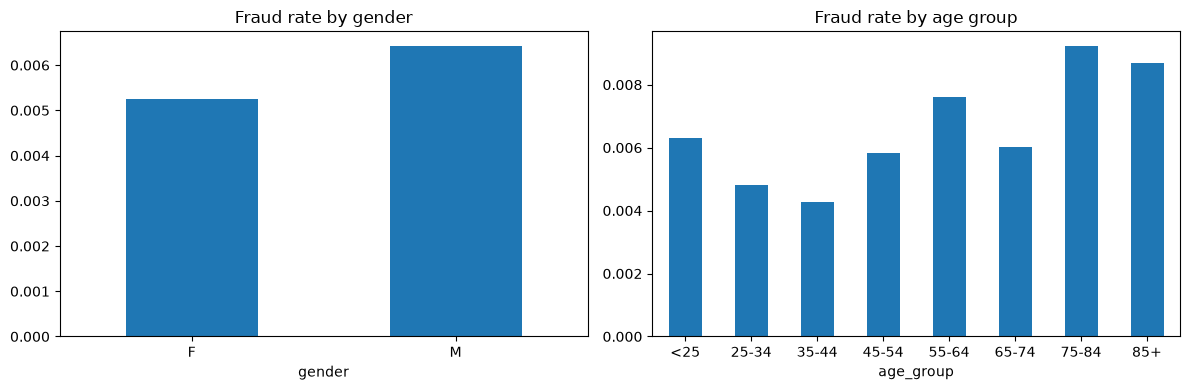

In [28]:
import matplotlib.pyplot as plt

# Fraud RATE per group (not counts: counts would mostly show which group shops more)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tx_users.groupby("gender")["is_fraud"].mean().plot.bar(ax=axes[0], title="Fraud rate by gender", rot=0)
tx_users.groupby("age_group", observed=True)["is_fraud"].mean().plot.bar(ax=axes[1], title="Fraud rate by age group", rot=0)
plt.tight_layout()
plt.show()

In [29]:
# Card-level check: only 983 people, so a few defrauded customers can move a group's rate.
# Here each card counts once: what share of cards in each group was defrauded at least once?
# (age_group = age at the card's first transaction)
cards = tx_users.groupby("cc_num").agg(
    gender=("gender", "first"),
    age_group=("age_group", "first"),
    defrauded=("is_fraud", "max"),
)
print(cards.groupby("gender")["defrauded"].agg(share_defrauded="mean", cards="size"))
print(cards.groupby("age_group", observed=True)["defrauded"].agg(share_defrauded="mean", cards="size"))

        share_defrauded  cards
gender                        
F              0.764588    497
M              0.786008    486
           share_defrauded  cards
age_group                        
<25               0.817204     93
25-34             0.751323    189
35-44             0.743750    160
45-54             0.772487    189
55-64             0.810976    164
65-74             0.715909     88
75-84             0.836066     61
85+               0.820513     39


### Age & gender findings

_Fill in after running the cells above:_
- **Gender:** fraud rate F = 0.764, M = 0.786 → difference is small, gender is slightly affecting  the distribution, Males are in higher rate
- **Age:** highest-risk group 75-84 (61 cards), lowest 65-74 → the aged people are more likely to get frauded
- **Card level:** share of defrauded cards per group confirms / contradicts the transaction level
- **Decision:** use as model features? (association ≠ should use — fairness)

In [30]:
from fraud_detection.features import add_transaction_features


In [31]:
tx_a = add_transaction_features(transactions)
# tx_a[["trans_date_trans_time", "category", "hour", "day_of_week", "is_online"]].head()
tx_a.head()


,trans_num,cc_num,trans_date_trans_time,category,merchant,amt,merch_lat,merch_long,is_fraud,hour,day_of_week,is_online
0,0b242abb623afc578575680df30655b9,2703186189652095,2019-01-01 00:00:18,misc_net,"fraud_Rippin, Kub and Mann",4.97,36.011293,-82.048315,0,0,1,1
1,1f76529f8574734946361c461b024d99,630423337322,2019-01-01 00:00:44,grocery_pos,"fraud_Heller, Gutmann and Zieme",107.23,49.159047,-118.186462,0,0,1,0
2,a1a22d70485983eac12b5b88dad1cf95,38859492057661,2019-01-01 00:00:51,entertainment,fraud_Lind-Buckridge,220.11,43.150704,-112.154481,0,0,1,0
3,6b849c168bdad6f867558c3793159a81,3534093764340240,2019-01-01 00:01:16,gas_transport,"fraud_Kutch, Hermiston and Farrell",45.00,47.034331,-112.561071,0,0,1,0
4,a41d7549acf90789359a9aa5346dcb46,375534208663984,2019-01-01 00:03:06,misc_pos,fraud_Keeling-Crist,41.96,38.674999,-78.632459,0,0,1,0


In [32]:
tx_a.groupby("is_online")["is_fraud"].mean()


is_online
0    0.004351
1    0.013389
Name: is_fraud, dtype: float64

## Feature groups B (card history) & C (user lookup)

B uses only each card's **past** transactions (no leakage). C is looked up in `users`.
`age` is computed but excluded by default (tested later with an ablation).

In [33]:
from fraud_detection.features import (
    CARD_FEATURES, USER_FEATURES, OPTIONAL_FEATURES, add_card_features, add_user_features,
)

tx_abc = add_user_features(add_card_features(tx_a), users)
new_cols = CARD_FEATURES + USER_FEATURES + OPTIONAL_FEATURES
tx_abc[new_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
hours_since_prev_tx,1295692.0,9.023615,13.166938,0.000000,1.670278,4.600000,11.173056,3.726308e+02
tx_count_1h,1296675.0,0.189499,0.461718,0.000000,0.000000,0.000000,0.000000,6.000000e+00
tx_count_24h,1296675.0,3.884108,3.082072,0.000000,2.000000,3.000000,5.000000,3.500000e+01
amt_vs_card_mean,1295692.0,1.021116,2.657184,0.002176,0.157158,0.667422,1.203758,6.763881e+02
city_pop,1296675.0,88824.440563,301956.360689,23.000000,743.000000,2456.000000,20328.000000,2.906700e+06
age,1296675.0,45.495406,17.396980,13.000000,32.000000,43.000000,57.000000,9.500000e+01


In [34]:
# Sanity check: each card's FIRST transaction has no history -> NaN (expect 983 = number of cards)
tx_abc[new_cols].isna().sum()

hours_since_prev_tx    983
tx_count_1h              0
tx_count_24h             0
amt_vs_card_mean       983
city_pop                 0
age                      0
dtype: int64

In [35]:
# One card around its first fraud: the features should "light up" when the episode starts
card = 4613314721966
cols = ["trans_date_trans_time", "amt", "is_fraud"] + CARD_FEATURES
one = tx_abc[tx_abc["cc_num"] == card].reset_index(drop=True)
first_fraud = one.index[one["is_fraud"] == 1][0]
one.loc[first_fraud - 5: first_fraud + 5, cols]

,trans_date_trans_time,amt,is_fraud,hours_since_prev_tx,tx_count_1h,tx_count_24h,amt_vs_card_mean
0,2019-01-01 12:51:40,71.03,0,NaN,0,0,NaN
1,2019-01-02 01:06:37,281.06,1,12.249167,0,1,3.956920
2,2019-01-02 03:38:03,7.03,1,2.523889,0,2,0.039933
3,2019-01-02 13:38:08,844.80,1,10.001389,0,2,7.057251
4,2019-01-02 23:52:08,843.91,1,10.233333,0,3,2.803874
5,2019-01-03 22:21:15,942.62,1,22.485278,0,1,2.301509
6,2019-01-03 23:09:51,821.96,1,0.810000,1,2,1.649170


In [36]:
# Do the new features separate fraud from legitimate? Compare medians
tx_abc.groupby("is_fraud")[new_cols].median().T

is_fraud,0,1
hours_since_prev_tx,4.6175,1.363333
tx_count_1h,0.0000,0.000000
tx_count_24h,3.0000,4.000000
amt_vs_card_mean,0.6641,5.229653
city_pop,2456.0000,2623.000000
age,43.0000,47.000000


In [37]:
# Fraud rate by bucket: velocity (24h count) and amount relative to the card's usual spend
print(tx_abc.groupby(tx_abc["tx_count_24h"].clip(upper=10))["is_fraud"].mean().round(4))

ratio_bins = pd.cut(tx_abc["amt_vs_card_mean"], [0, 0.5, 1, 2, 5, 10, float("inf")])
tx_abc.groupby(ratio_bins, observed=True)["is_fraud"].agg(["size", "mean"])

tx_count_24h
0     0.0027
1     0.0035
2     0.0047
3     0.0061
4     0.0075
5     0.0084
6     0.0088
7     0.0086
8     0.0072
9     0.0056
10    0.0025
Name: is_fraud, dtype: float64


,size,mean
amt_vs_card_mean,,
"(0.0, 0.5]",544741,0.002917
"(0.5, 1.0]",327285,0.000623
"(1.0, 2.0]",287780,0.001418
"(2.0, 5.0]",111329,0.012342
"(5.0, 10.0]",15750,0.088571
"(10.0, inf]",8807,0.279437


In [38]:
from fraud_detection.config import FEATURES_FILE
from fraud_detection.split import time_split

features = pd.read_parquet(FEATURES_FILE)
train, val = time_split(features)
train["is_fraud"].agg(["size", "sum", "mean"]), val["is_fraud"].agg(["size", "sum", "mean"])


(size    1.037340e+06
 sum     5.968000e+03
 mean    5.753176e-03
 Name: is_fraud, dtype: float64,
 size    259335.000000
 sum       1538.000000
 mean         0.005931
 Name: is_fraud, dtype: float64)